![Nagłówek - Fundusze Europejskie dla Rozwoju Społecznego, Rzeczpospolita Polska, Dofinansowane Przez Unię Europejską i Politechnika Wrocławska](./img/header.png)

# Laboratorium kursu Wstęp do Sztucznej Inteligencji
## Reprezentacja wiedzy i zarządzanie nią

## Czym jest reprezentacja wiedzy?

Reprezentacja wiedzy to zestaw struktur i reguł (formalizmów) używanych do zapisania informacji o świecie w formie zrozumiałej dla programu komputerowego. Metody reprezentacji wiedzy są tworzone m.in. by:

* Umożliwić maszynom "rozumienie świata" i wnioskowanie.

* Zapewnić separację wiedzy (reguł i faktów) od reszty kodu, co ułatwia jego poprawianie i rozszerzanie.

* Ułatwić tworzenie i weryfikację systemów poprzez wykorzystanie czytelnych dla ludzi struktur. 

W Laboratorium 4 poznaliśmy bazę wiedzy złożoną z faktów i reguł. Teraz poznamy dwie inne formy reprezentacji wiedzy: grafy wiedzy i ramy. Grafy wiedzy działają m.in. w wyszukiwarkach (np. Google Knowledge Graph), a wiedzę z nich można wykorzystywać razem z dużymi modelami językowymi. Pamiętaj, że sposoby reprezentacji nie istnieją w odosobnieniu, a w rzeczywistych systemach często są stosowane razem i wspólnie tworzą działającą całość.

## Sieci semantyczne i Grafy wiedzy

Tabele są praktyczne, gdy mamy dane o stałej strukturze, oraz gdy prowadzimy na nich proste obliczenia. Gdy obiekty łączy wiele różnych relacji, a pytania wymagają kojarzenia wielu powiązań, np. „którzy przewoźnicy używają pociągów producenta z siedzibą w Bydgoszczy?”, tabele okazują się problematyczne, ponieważ każdy taki krok wymaga łączenia kolejnych tabel. W takim przypadku wygodniej użyć grafów. Tabele i grafy to dwa narzędzia, podobnie jak pociągi i samoloty są dwoma rodzajami pojazdów - każde ma swoje wady i zalety. Jednym z typów grafów są sieci semantyczne i grafy wiedzy. 

Na wykładzie miałeś okazję zapoznać się z pojęciem sieci semantycznej (Semantic Network) - jedną z metod reprezentacji wiedzy wykorzystującą grafy.
Jej założenia przypominają mapę myśli - łączy koncepty za pomocą relacji definiujących ich właściwości, np. `Pociąg -JEST_RODZAJEM-> Pojazd` lub `Pociąg -PORUSZA_SIĘ_PO-> Tory`.

Obecną ewolucją sieci semantycznych są grafy wiedzy. Klasyczne sieci semantyczne nie mają sformalizowanej semantyki, co często skutkowało bałaganem. Klasycznym przykładem jest używanie tej samej relacji `JEST` do łączenia zarówno konkretnych obiektów (`Wrocław -JEST-> Miasto`) oraz bardziej ogólnych pojęć (`Miasto -JEST-> Miejsce`). W grafach wiedzy często oddziela się **fakty o obiektach** (np. `Wrocław -lot-> Warszawa`, `Wrocław -JEST-> Miasto`) od **ontologii**, czyli opisu pojęć i relacji, np. klas obiektów, zależności między pojęciami ($\text{miasto} \subset \text{miejsce}$), czy zależności między relacjami ($\text{lot} \subset \text{połączenie}$). Dzięki nim system może **wywnioskować nowe fakty**, np. z `Wrocław -lot-> Warszawa` wynika `Wrocław -połączenie-> Warszawa`. Ontologia pozwala też wykrywać dane sprzeczne z opisem pojęć i dzięki temu chronić graf przed nielogicznymi wpisami. 

Gdzie są używane grafy wiedzy? Wszędzie tam, gdzie relacje są istotne. Bazy danych oparte o grafy wiedzy mogą służyć do wyszukiwania faktów o świecie (`Hala Stulecia -znajduje się w-> Wrocław`), leków oddziałujących na konkretne białka (`lek X -jest inhibitorem-> białko Y -bierze udział w replikacji-> wirus Z`) i wielu innych zastosowań. 

Próba implementacji nowoczesnego grafu wiedzy na obecnym etapie to jednak skok na bardzo głęboką wodę, dlatego w ramach laboratorium zbudujemy prosty graf wiedzy z niewielkim fragmentem ontologii i przeprowadzimy proste wnioskowanie.


### Implementacja w Python

Podstawowym sposobem implementacji grafu wiedzy są trójki `Podmiot - Relacja - Obiekt`, np. `(Pendolino, Producent, Alstom)`, jednak popularność grafów jako metody reprezentacji wiedzy doprowadziła do powstania wielu bibliotek w Python pozwalających na łatwą pracę z nimi. Jedną z najpopularniejszych jest `networkx`.  

In [2]:
import networkx as nx

# TWORZENIE GRAFU WIEDZY
# Używamy grafu skierowanego (DiGraph), ponieważ relacje mają kierunek
G = nx.DiGraph()

# Dodajemy węzły (byty)
G.add_nodes_from([
    # Fakty
    ("Pesa", {"typ": "Producent"}),
    ("Newag", {"typ": "Producent"}),
    ("Bydgoszcz", {"typ": "Miasto"}),
    ("Nowy Sącz", {"typ": "Miasto"}),
    
    ("Pesa Dart", {"typ": "ModelPojazdu"}),
    ("Pesa Elf 2", {"typ": "ModelPojazdu"}),
    ("Newag Impuls", {"typ": "ModelPojazdu"}),

    ("PKP Intercity", {"typ": "Operator"}),
    ("POLREGIO", {"typ": "Operator"}),
    ("Koleje Dolnośląskie", {"typ": "Operator"}),

    # W nowoczesnym systemie oddzielilibyśmy pojęcia ogólne (ontologia), 
    # jednak tutaj reprezentujemy je razem z powyższymi faktami
    ("EZT", {"typ": "KlasaPojazdu"}), # Elektryczny Zespół Trakcyjny
    ("SZT", {"typ": "KlasaPojazdu"}), # Spalinowy Zespół Trakcyjny

])

# Dodajemy krawędzie (Relacje)
G.add_edges_from([
    # Relacje Producent -> Model
    ("Pesa", "Pesa Dart", {"relacja": "WYPRODUKOWAŁ"}), # Czytamy jako "Pesa WYPRODUKOWAŁ Pesa Dart"
    ("Pesa", "Pesa Elf 2", {"relacja": "WYPRODUKOWAŁ"}),
    ("Newag", "Newag Impuls", {"relacja": "WYPRODUKOWAŁ"}),
    
    # Relacje Model -> Typ
    ("Pesa Dart", "EZT", {"relacja": "JEST_TYPU"}),
    ("Pesa Elf 2", "EZT", {"relacja": "JEST_TYPU"}),
    ("Newag Impuls", "EZT", {"relacja": "JEST_TYPU"}),
    
    # Relacje Operator -> Model
    ("PKP Intercity", "Pesa Dart", {"relacja": "UŻYWA"}),
    ("POLREGIO", "Pesa Elf 2", {"relacja": "UŻYWA"}),
    ("Koleje Dolnośląskie", "Pesa Elf 2", {"relacja": "UŻYWA"}),
    ("Koleje Dolnośląskie", "Newag Impuls", {"relacja": "UŻYWA"}),
    
    # Relacje Atrybutowe (Lokalizacja)
    ("Pesa", "Bydgoszcz", {"relacja": "MA_SIEDZIBĘ_W"}),
    ("Newag", "Nowy Sącz", {"relacja": "MA_SIEDZIBĘ_W"})
])

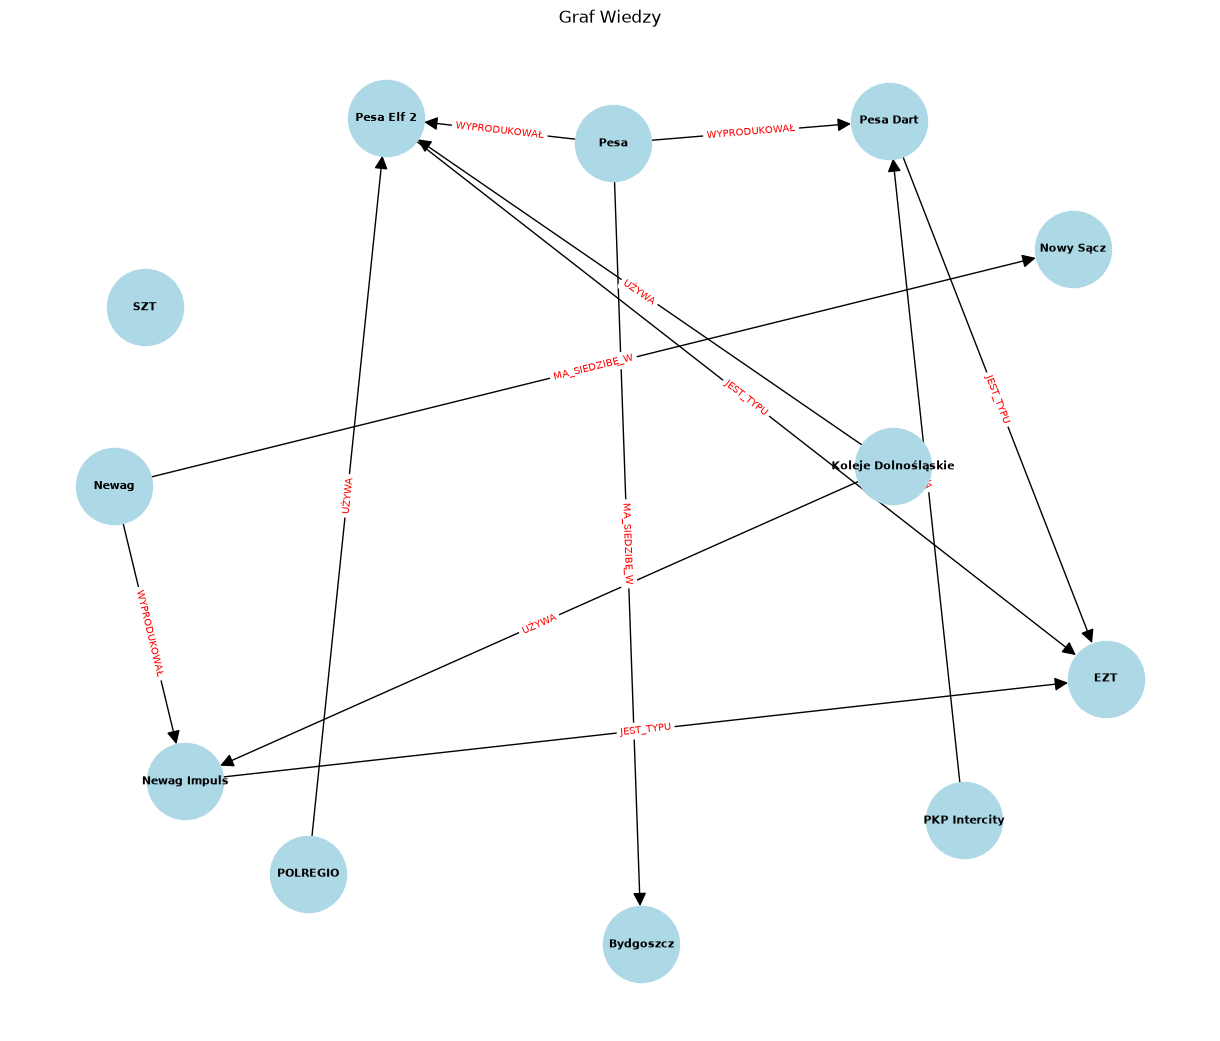

Podmiot,Relacja,Obiekt
Pesa,WYPRODUKOWAŁ,Pesa Dart
Pesa,WYPRODUKOWAŁ,Pesa Elf 2
Pesa,MA_SIEDZIBĘ_W,Bydgoszcz
Newag,WYPRODUKOWAŁ,Newag Impuls
Newag,MA_SIEDZIBĘ_W,Nowy Sącz
Pesa Dart,JEST_TYPU,EZT
Pesa Elf 2,JEST_TYPU,EZT
Newag Impuls,JEST_TYPU,EZT
PKP Intercity,UŻYWA,Pesa Dart
POLREGIO,UŻYWA,Pesa Elf 2


In [3]:
import matplotlib.pyplot as plt
from helpers import display_accessible_graph
plt.figure(figsize=(12, 10)) # Ustaw rozmiar rysunku

# Pozycje węzłów - algorytm 'spring_layout' zazwyczaj daje dobre rezultaty
# Możesz eksperymentować z innymi (są opisane w dokumentacji)
pos = nx.spring_layout(G, k=8, iterations=200)

# Rysowanie węzłów i krawędzi
nx.draw(G, pos, 
        with_labels=True, # Pokaż etykiety węzłów
        node_color='lightblue', 
        node_size=3000, 
        font_size=8, 
        font_weight='bold', 
        arrowsize=20) # Ustaw rozmiar strzałek

# Pobieranie etykiet krawędzi (relacji)
edge_labels = nx.get_edge_attributes(G, 'relacja')

# Rysowanie etykiet krawędzi
nx.draw_networkx_edge_labels(G, pos, 
                             edge_labels=edge_labels, 
                             font_color='red', 
                             font_size=7)

# Jeśli wykres nie będzie czytelny, spróbuj uruchomić kod ponownie lub zmienić parametry layoutu
plt.title("Graf Wiedzy")
plt.axis('off') # Wyłącz osie
plt.show()
display_accessible_graph(G)


In [4]:
# PRZESZUKIWANIE "BRUTE FORCE" (Ręczne)
# Przeglądamy krawędzie wchodzące lub wychodzące z jednego węzła 
# i wybieramy te o danej relacji

print("\n--- ZAPYTANIE 1: Kto używa pociągów 'Pesa Dart'? ---")
# Logika: Znajdź krawędzie WCHODZĄCE do 'Pesa Dart'
#         z relacją 'UŻYWA'.

for (start_node, end_node, data) in G.in_edges("Pesa Dart", data=True):
    if data.get('relacja') == 'UŻYWA':
        print(f" -> {start_node}")

# ---
print("\n--- ZAPYTANIE 2: Jakie pociągi wyprodukował 'Newag'? ---")
# Logika: Znajdź krawędzie WYCHODZĄCE z 'Newag'
#         z relacją 'WYPRODUKOWAŁ'.

for (start_node, end_node, data) in G.out_edges("Newag", data=True):
    if data.get('relacja') == 'WYPRODUKOWAŁ':
        print(f"  -> {end_node}")

# ---
print("\n--- ZAPYTANIE 3: Jakie pociągi są typu 'EZT' (elektryczne)? ---")
# Logika: Znajdź krawędzie WCHODZĄCE do 'EZT'
#         z relacją 'JEST_TYPU'.

for (start_node, end_node, data) in G.in_edges("EZT", data=True):
    if data.get('relacja') == 'JEST_TYPU':
        print(f"  -> {start_node}")

# ---
print("\n--- ZAPYTANIE 4 (Złożone, 2 etapy): Jacy operatorzy używają pociągów producenta 'Pesa'? ---")
# Logika (2 etapy):
# 1. Znajdź wszystkie modele wyprodukowane przez 'Pesa'.
# 2. Dla każdego modelu, znajdź operatora, który go 'UŻYWA'.

print("Etap 1: Szukam modeli producenta 'Pesa'...")
modele_producenta = []
# Etap 1: Modele producenta 'Pesa', czyli krawędzie wychodzące z 'Pesa' o relacji 'WYPRODUKOWAŁ'
for (start_node, end_node, data) in G.out_edges("Pesa", data=True):
    if data.get('relacja') == 'WYPRODUKOWAŁ':
        print(f"  -> Znalazłem model: {end_node}")
        modele_producenta.append(end_node)

# Etap 2: Dla każdego znalezionego modelu, szukamy krawędzi wchodzących z relacją 'UŻYWA'
print("\nEtap 2: Sprawdzam, kto używa tych modeli...")
for model in modele_producenta:
    for (start_node, end_node, data) in G.in_edges(model, data=True):
        if data.get('relacja') == 'UŻYWA':
            print(f"  -> Model {model} jest używany przez: {start_node}")


--- ZAPYTANIE 1: Kto używa pociągów 'Pesa Dart'? ---
 -> PKP Intercity

--- ZAPYTANIE 2: Jakie pociągi wyprodukował 'Newag'? ---
  -> Newag Impuls

--- ZAPYTANIE 3: Jakie pociągi są typu 'EZT' (elektryczne)? ---
  -> Pesa Dart
  -> Pesa Elf 2
  -> Newag Impuls

--- ZAPYTANIE 4 (Złożone, 2 etapy): Jacy operatorzy używają pociągów producenta 'Pesa'? ---
Etap 1: Szukam modeli producenta 'Pesa'...
  -> Znalazłem model: Pesa Dart
  -> Znalazłem model: Pesa Elf 2

Etap 2: Sprawdzam, kto używa tych modeli...
  -> Model Pesa Dart jest używany przez: PKP Intercity
  -> Model Pesa Elf 2 jest używany przez: POLREGIO
  -> Model Pesa Elf 2 jest używany przez: Koleje Dolnośląskie


Zapytania 1 - 3 po prostu odczytują fakty zapisane w grafie (bezpośrednia krawędź). Każda krawędź to po prostu fakt z dwuargumentowym predykatem z Laboratorium 4, np. `wyprodukowal(pesa, pesa_dart).` 

Zapytanie 4 wymaga informacji, której w grafie nie ma wprost, więc wymaga przeprowadzenia wnioskowania. W notacji z Laboratorium 4 odpowiadałaby mu reguła 

`uzywa_pociagow_producenta(Operator, Producent) :- wyprodukowal(Producent, Model), uzywa(Operator, Model).` 

i zapytanie 

`?- uzywa_pociagow_producenta(Operator, pesa).` 

Tutaj zmienna `Operator` w zapytaniu oznacza: "znajdź wszystkich operatorów, dla których cel da się udowodnić". Każdy etap zapytania w kodzie powyżej odpowiada jednemu warunkowi w ciele reguły.

### Wnioskowanie z hierarchii pojęć

Zapytania powyżej są ograniczone, ponieważ miały z góry znaną liczbę etapów. Dodanie ontologii pozwoli nam przeprowadzić bardziej zaawansowane przeszukiwanie. 

Dodajmy do grafu następującą hierarchię: 
- EZT i SZT są rodzajami zespołów trakcyjnych
- zespół trakcyjny jest rodzajem pojazdu kolejowego. 

Taką relację między pojęciami oznaczymy `JEST_RODZAJEM` (to ⊂ z opisu ontologii). Relacja `JEST_TYPU` łączy natomiast obiekt opisany w grafie (tu model pociągu) z jego klasą. Dokładnie taki podział był opisany w przykładzie powyżej: `Wrocław -JEST-> Miasto` to co innego niż `Miasto -JEST-> Miejsce`.

Czy Pesa Dart jest pojazdem kolejowym? Takiej krawędzi w grafie nie ma, ale odpowiedź wynika z łańcucha:

`Pesa Dart -JEST_TYPU-> EZT -JEST_RODZAJEM-> Zespół trakcyjny -JEST_RODZAJEM-> Pojazd kolejowy`

Hierarchia może mieć dowolnie wiele poziomów, więc nie wystarczy zapytanie o stałej liczbie etapów. Funkcja `wszystkie_klasy` przeszukuje hierarchię wszerz (BFS): najpierw sprawdza klasy bezpośrednie, potem ich klasy ogólniejsze i tak dalej, aż nie trafi na koniec ścieżki. To ta sama idea co reguła reachable z przykładu 1 w Laboratorium 4 - w każdym kroku stosujemy tę samą regułę rekurencyjnie, a każdy krok wykorzystuje jeden fakt, czyli krawędź JEST_TYPU lub JEST_RODZAJEM. Regułę zapisaliśmy w kodzie funkcji.

In [5]:
# HIERARCHIA POJĘĆ (fragment ontologii) dopisana do grafu z przykładu
G.add_nodes_from([
    ("Zespół trakcyjny", {"typ": "KlasaPojazdu"}),
    ("Pojazd kolejowy", {"typ": "KlasaPojazdu"}),
])
G.add_edges_from([
    ("EZT", "Zespół trakcyjny", {"relacja": "JEST_RODZAJEM"}),
    ("SZT", "Zespół trakcyjny", {"relacja": "JEST_RODZAJEM"}),
    ("Zespół trakcyjny", "Pojazd kolejowy", {"relacja": "JEST_RODZAJEM"}),
])

def wszystkie_klasy(G, node):
    """
    Zwraca wszystkie klasy, do których należy węzeł: bezpośrednio (JEST_TYPU)
    i pośrednio, idąc w górę hierarchii (JEST_RODZAJEM).
    Przeszukiwanie wszerz (BFS) z zapamiętywaniem odwiedzonych węzłów, jak w Laboratorium 2.
    """
    found = []
    queue = [node]   # kolejka węzłów do sprawdzenia
    checked = [node]
    while queue:      # dopóki kolejka nie jest pusta
        biezacy = queue.pop(0)   # wyjmij pierwszy węzeł z kolejki
        for (_, nastepny, data) in G.out_edges(biezacy, data=True):
            if data.get('relacja') in ('JEST_TYPU', 'JEST_RODZAJEM') and nastepny not in checked:
                checked.append(nastepny)
                found.append(nastepny)
                queue.append(nastepny)
    return found

print("--- PYTANIE 1: Do jakich klas należy 'Pesa Dart'? ---")
print(wszystkie_klasy(G, "Pesa Dart"))

print("\n--- PYTANIE 2: Czy 'Pesa Dart' jest pojazdem kolejowym? ---")
print("Pojazd kolejowy" in wszystkie_klasy(G, "Pesa Dart"))

print("\n--- PYTANIE 3: Które modele pociągów są pojazdami kolejowymi? ---")
for wezel, dane in G.nodes(data=True):
    if dane.get("typ") == "ModelPojazdu" and "Pojazd kolejowy" in wszystkie_klasy(G, wezel):
        print(f"  -> {wezel}")

--- PYTANIE 1: Do jakich klas należy 'Pesa Dart'? ---
['EZT', 'Zespół trakcyjny', 'Pojazd kolejowy']

--- PYTANIE 2: Czy 'Pesa Dart' jest pojazdem kolejowym? ---
True

--- PYTANIE 3: Które modele pociągów są pojazdami kolejowymi? ---
  -> Pesa Dart
  -> Pesa Elf 2
  -> Newag Impuls


### 🧑‍🎓 Zadanie

Na podstawie powyższego przykładu stwórz graf wiedzy na dowolny, wybrany przez siebie temat (np. Twoje hobby, podziwiana przez Ciebie postać, Wrocławskie MPK...). Graf musi być jednak inny niż w przykładzie powyżej. Informacje niezbędne do stworzenia grafu wyszukaj w internecie. Upewnij się, że graf zawiera co najmniej 10 węzłów.
Graf powinien mieć formę pozwalającą na wykonanie poniższego zadania. Wyświetl graf (nie przejmuj się, jeżeli wykres nie będzie w pełni czytelny).

**Zapytania.** Postaw 3 pytania, wymagające:

1. jednoetapowego zapytania (odczyt faktu – jedna krawędź),
2. dwuetapowego wnioskowania,
3. trzyetapowego wnioskowania,

i znajdź na nie odpowiedź w sposób analogiczny do tego w powyższym przykładzie. W każdym wnioskowaniu wieloetapowym liczba etapów powinna być równa długości najkrótszej ścieżki między węzłem, od którego zaczynasz, a węzłem z odpowiedzią (liczbie krawędzi, **bez względu na ich kierunek**). Na przykład w zapytaniu 4 z przykładu: Pesa $\rightarrow$ Pesa Dart $\leftarrow$ PKP Intercity to dwie krawędzie, więc dwa etapy.

In [6]:
# Miejsce na definicję grafu wiedzy
import networkx as nx

# --- 1. TWORZENIE GRAFU WIEDZY ---
G = nx.DiGraph()

# Dodajemy węzły (byty). Nazw atrybutów "typ" i "relacja" nie zmieniaj –
# korzystają z nich funkcje display_accessible_graph i wszystkie_klasy.
G.add_nodes_from([
    # Fakty - Gry
    ("Minecraft", {"typ": "Gra"}),
    ("CS2", {"typ": "Gra"}),
    ("TF2", {"typ": "Gra"}),
    ("Skyrim V", {"typ": "Gra"}),
    ("Witcher 3", {"typ": "Gra"}),

    # Fakty - Wydawcy / Studia
    ("Mojang", {"typ": "Wydawca"}),
    ("Valve", {"typ": "Wydawca"}),
    ("CD Projekt Red", {"typ": "Wydawca"}),
    ("Bethesda", {"typ": "Wydawca"}),

    # Fakty - Założyciele (Osoby)
    ("Markus Persson", {"typ": "Osoba"}),      
    ("Gabe Newell", {"typ": "Osoba"}),         
    ("Mike Harrington", {"typ": "Osoba"}),     
    ("Marcin Iwiński", {"typ": "Osoba"}),      
    ("Michał Kiciński", {"typ": "Osoba"}),     
    ("Christopher Weaver", {"typ": "Osoba"}),  

    # Pojęcia ogólne (Gatunki / Typy gier)
    ("Survival", {"typ": "TypGry"}),
    ("FPS", {"typ": "TypGry"}),
    ("RPG", {"typ": "TypGry"}),
])

# Dodajemy krawędzie (Relacje)
G.add_edges_from([
    # Relacje Osoba -> Wydawca (Kto założył studio)
    ("Markus Persson", "Mojang", {"relacja": "ZAŁOŻYŁ"}),
    ("Gabe Newell", "Valve", {"relacja": "ZAŁOŻYŁ"}),
    ("Mike Harrington", "Valve", {"relacja": "ZAŁOŻYŁ"}),
    ("Marcin Iwiński", "CD Projekt Red", {"relacja": "ZAŁOŻYŁ"}),
    ("Michał Kiciński", "CD Projekt Red", {"relacja": "ZAŁOŻYŁ"}),
    ("Christopher Weaver", "Bethesda", {"relacja": "ZAŁOŻYŁ"}),

    # Relacje Wydawca -> Gra
    ("Mojang", "Minecraft", {"relacja": "WYDAŁ"}),
    ("Valve", "CS2", {"relacja": "WYDAŁ"}),
    ("Valve", "TF2", {"relacja": "WYDAŁ"}),
    ("Bethesda", "Skyrim V", {"relacja": "WYDAŁ"}),
    ("CD Projekt Red", "Witcher 3", {"relacja": "WYDAŁ"}),

    # Relacje Gra -> TypGry
    ("Minecraft", "Survival", {"relacja": "JEST_TYPU"}),
    ("CS2", "FPS", {"relacja": "JEST_TYPU"}),
    ("TF2", "FPS", {"relacja": "JEST_TYPU"}),
    ("Skyrim V", "RPG", {"relacja": "JEST_TYPU"}),
    ("Witcher 3", "RPG", {"relacja": "JEST_TYPU"}),
])


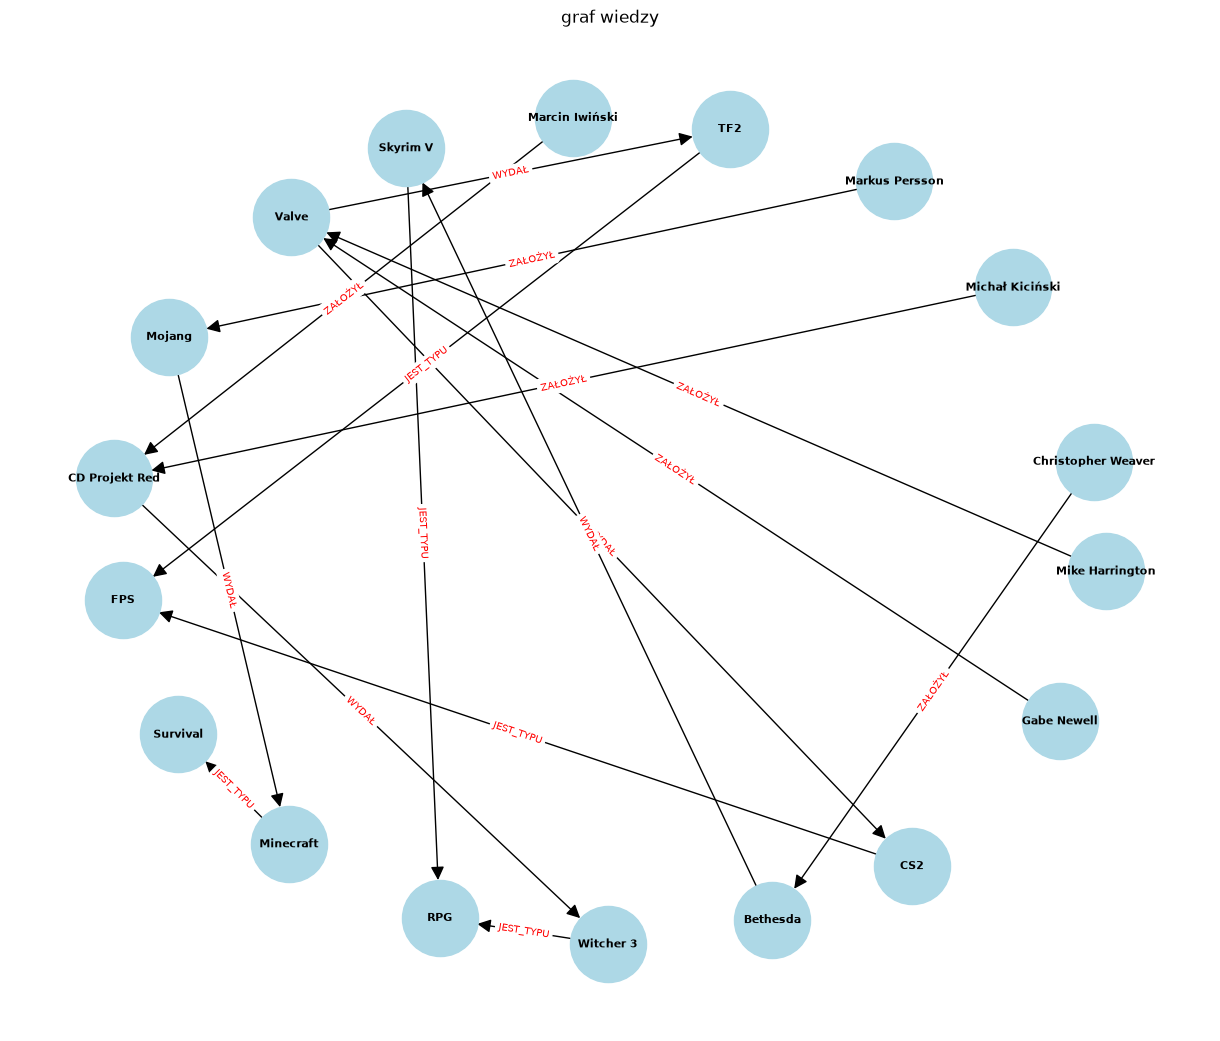

Podmiot,Relacja,Obiekt
Minecraft,JEST_TYPU,Survival
CS2,JEST_TYPU,FPS
TF2,JEST_TYPU,FPS
Skyrim V,JEST_TYPU,RPG
Witcher 3,JEST_TYPU,RPG
Mojang,WYDAŁ,Minecraft
Valve,WYDAŁ,CS2
Valve,WYDAŁ,TF2
CD Projekt Red,WYDAŁ,Witcher 3
Bethesda,WYDAŁ,Skyrim V


In [7]:
# Wizualizacja grafu wiedzy
plt.figure(figsize=(12, 10)) # Ustaw rozmiar rysunku

# Pozycje węzłów - algorytm 'spring_layout' zazwyczaj daje dobre rezultaty
# Możesz eksperymentować z innymi (są opisane w dokumentacji)
pos = nx.spring_layout(G, k=8, iterations=200)

# Rysowanie węzłów i krawędzi
nx.draw(G, pos, 
        with_labels=True, # Pokaż etykiety węzłów
        node_color='lightblue', 
        node_size=3000, 
        font_size=8, 
        font_weight='bold', 
        arrowsize=20) # Ustaw rozmiar strzałek

# Pobieranie etykiet krawędzi (relacji)
edge_labels = nx.get_edge_attributes(G, 'relacja')

# Rysowanie etykiet krawędzi
nx.draw_networkx_edge_labels(G, pos, 
                             edge_labels=edge_labels, 
                             font_color='red', 
                             font_size=7)

plt.title("graf wiedzy")
plt.axis('off')
plt.show()

display_accessible_graph(G)

In [8]:
# PRZESZUKIWANIE "BRUTE FORCE" (Ręczne)
# Przeglądamy krawędzie wchodzące lub wychodzące z jednego węzła 
# i wybieramy te o danej relacji

print("\n--- ZAPYTANIE 1: Jaki jest typ gry 'Minecraft'? ---")


for (start_node, end_node, data) in G.out_edges("Minecraft", data=True):
    if data.get('relacja') == 'JEST_TYPU':
        print(f" -> {end_node}")

print("\n--- ZAPYTANIE 2 (Złożone, 2 etapy): Jakiego typu gry proukuje bethesda? ---")
# Logika (2 etapy):


print("Etap 1: Szukam gier wyprodukowanych przez 'bethesda'...")
gry_stuida = []
for (start_node, end_node, data) in G.out_edges("Bethesda", data=True):
    if data.get('relacja') == 'WYDAŁ':
        print(f"  -> Znalazłem gre: {end_node}")
        gry_stuida.append(end_node)

# Etap 2: szukam jekie sa typy znalezionych gier
print("\nEtap 2: Sprawdzam jaki jest typ tych gier...")
for game in gry_stuida:
    for (start_node, end_node, data) in G.out_edges(game, data=True):
        if data.get('relacja') == 'JEST_TYPU':
            print(f"  -> Gra {game} jest typu: {end_node}")


print("\n--- ZAPYTANIE 3 (Złożone, 3 etapy): Kto założył studia które produkją gry typu 'FPS'? ---")
# Logika (2 etapy):


print("Etap 1: Szukam gier typu 'fps'")
gry_fps = []
for (start_node, end_node, data) in G.in_edges("FPS", data=True):
    if data.get('relacja') == 'JEST_TYPU':
        print(f"  -> Znalazłem gre: {start_node}")
        gry_fps.append(start_node)

print("\nEtap 2: Sprawdzam jakei studia wydały te gry...")
studia_gier_fps = []
for game in gry_fps:
    for (start_node, end_node, data) in G.in_edges(game, data=True):
        if data.get('relacja') == 'WYDAŁ':
            print(f"  -> Gra {game} jest wydana przez: {start_node}")
            studia_gier_fps.append(start_node)
studia_gier_fps =  list(set(studia_gier_fps))      
for studio in studia_gier_fps:
    for (sn,en,data) in G.in_edges(studio, data=True):
        if data.get('relacja') == 'ZAŁOŻYŁ':
            print(f"  -> Studio {studio} jest założone przez: {sn}")




--- ZAPYTANIE 1: Jaki jest typ gry 'Minecraft'? ---
 -> Survival

--- ZAPYTANIE 2 (Złożone, 2 etapy): Jakiego typu gry proukuje bethesda? ---
Etap 1: Szukam gier wyprodukowanych przez 'bethesda'...
  -> Znalazłem gre: Skyrim V

Etap 2: Sprawdzam jaki jest typ tych gier...
  -> Gra Skyrim V jest typu: RPG

--- ZAPYTANIE 3 (Złożone, 3 etapy): Kto założył studia które produkją gry typu 'FPS'? ---
Etap 1: Szukam gier typu 'fps'
  -> Znalazłem gre: CS2
  -> Znalazłem gre: TF2

Etap 2: Sprawdzam jakei studia wydały te gry...
  -> Gra CS2 jest wydana przez: Valve
  -> Gra TF2 jest wydana przez: Valve
  -> Studio Valve jest założone przez: Gabe Newell
  -> Studio Valve jest założone przez: Mike Harrington


### 🧑‍🎓 Zadanie

**Hierarchia pojęć.** Dodaj do swojego grafu hierarchię co najmniej trzech pojęć, np. `Planeta skalista -JEST_RODZAJEM-> Planeta -JEST_RODZAJEM-> Ciało niebieskie`. Obiekty połącz z ich klasami relacją `JEST_TYPU`, a klasy z klasami ogólniejszymi relacją `JEST_RODZAJEM`, tak aby funkcja `wszystkie_klasy` działała bez zmian. Zadaj pytanie, na które odpowiedzi nie ma w grafie wprost (np. „Czy X jest Y?” albo „Które obiekty są Y?”), uruchom kod i wyświetl wyniki.

W 2–3 zdaniach wyjaśnij:
* czym ta odpowiedź różni się od odczytania faktu z grafu
* dlaczego `JEST_TYPU` i `JEST_RODZAJEM` to dwie różne relacje

*Podpowiedź: Możesz zmodyfikować funkcję `wszystkie_klasy` tak, aby dla każdej znalezionej klasy zwracała też uzasadnienie, czyli łańcuch krawędzi, który do niej prowadzi, np. `Pesa Dart -JEST_TYPU-> EZT -JEST_RODZAJEM-> Zespół trakcyjny`.*

In [17]:
# Miejsce na kod z hierarchią pojęć
# 1. Dodaj do G węzły klas, krawędzie JEST_TYPU i krawędzie JEST_RODZAJEM
# (co najmniej trzy poziomy hierarchii).
# 2. Użyj funkcji wszystkie_klasy, aby odpowiedzieć na swoje pytanie.

# HIERARCHIA POJĘĆ (fragment ontologii) dopisana do grafu z przykładu
G.add_nodes_from([                                                                                                                  
    ("Gra akcji", {"typ": "KlasaGry"}),                                                                                             
    ("Gra komputerowa", {"typ": "KlasaGry"}),                                                                                       
    ("Oprogramowanie rozrywkowe", {"typ": "KlasaGry"}),                                                                             
])
G.add_edges_from([                                                                                                                  
    ("FPS", "Gra akcji", {"relacja": "JEST_RODZAJEM"}),                                                                             
    ("Survival", "Gra akcji", {"relacja": "JEST_RODZAJEM"}),                                                                        
    ("Gra akcji", "Gra komputerowa", {"relacja": "JEST_RODZAJEM"}),                                                                 
    ("RPG", "Gra komputerowa", {"relacja": "JEST_RODZAJEM"}),                                                                       
    ("Gra komputerowa", "Oprogramowanie rozrywkowe", {"relacja": "JEST_RODZAJEM"}),                                                 
]) 

print("czy miencraft to gra komputerowa")

if "Gra komputerowa" in wszystkie_klasy(G,"Minecraft"):
    print("tak")
else:
    print("nie")


czy miencraft to gra komputerowa
tak


 gdy odczytujamy fakty z grafu sprawdzamy bezpośrednich sąsiadów badanego obiektu, 

## Ramy

W prostych sieciach semantycznych węzły są tylko punktami połączonymi relacjami (np. punkty Newag i Nowy Sącz). Ramy wiedzy stanowią bogatszy sposób reprezentacji wiedzy.

Ramy to złożone struktury opisujące obiekty lub sytuacje za pomocą atrybutów (gniazd, slotów) i ich wartości. Ramy służą do przechowywania faktów, powiązanych wartości, reguł dziedziczenia oraz procedur wywoływanych przy odczycie lub zmianie wartości atrybutów.
Na przykład rama Pociąg może mieć atrybuty takie jak: Napęd, Liczba Wagonów czy Przewoźnik.

Ważne cechy wyróżniające ramy to:
- Wartości domyślne: Dla pociągu, domyślnie zakładalibyśmy, że porusza się po torach, nawet bez wprowadzania tej wiedzy osobno do systemu. Oczywiście w razie potrzeby taką wartość można zastąpić inną. Wartość domyślna opisuje to, co typowe, ale może mieć wyjątki (ptaki zwykle latają, ale pingwin nie). Cechy, która wynika z definicji pojęcia (elektryczny zespół trakcyjny ma z definicji napęd elektryczny) nie nadpisujemy, ponieważ obiekt bez tej cechy należy do innej klasy.
- Procedury: Gniazda mogą zawierać procedury uruchamiane automatycznie przy odczycie wartości albo przy jej wpisaniu, np. gniazdo `Cena biletu` może mieć procedurę, która oblicza cenę dla danej trasy, gdy ktoś o nią zapyta.
- rama potomna dziedziczy gniazda po ramie nadrzędnej, a ta po swojej ramie nadrzędnej, np. `Pesa Dart` dziedziczy po ramie `EZT`, a `EZT` po ramie `Pojazd kolejowy`. Oczywiście rama dziedzicząca może nadpisać odziedziczoną wartość i mieć np. wyższą prędkość niż rama nadrzędna.

Powyższy opis może brzmieć znajomo, jeżeli wiesz czym jest programowanie obiektowe (klasy, dziedziczenie, właściwości i metody). Podobieństwo nie jest przypadkowe: ramy i programowanie obiektowe rozwijały się w podobnym czasie i twórcy inspirowali się na wzajem. Ich cele są jednak różne: ramy mają czytelnie opisywać wiedzę, a obiekty porządkować kod programu. 

In [10]:
# Definicja Silnika - Ramy Wiedzy

class RamaWiedzy:
    def __init__(self, nazwa, rodzic=None):
        self.nazwa = nazwa
        self.rodzic = rodzic  
        self.gniazda = {}     

    def dodaj_gniazdo(self, nazwa_gniazda, wartosc_domyslna=None, procedura=None):
        self.gniazda[nazwa_gniazda] = {
            'wartosc': None,             
            'domyslna': wartosc_domyslna,
            'procedura': procedura       
        }

    def wypelnij_gniazdo(self, nazwa_gniazda, wartosc):
        if nazwa_gniazda not in self.gniazda:
            self.dodaj_gniazdo(nazwa_gniazda)
        self.gniazda[nazwa_gniazda]['wartosc'] = wartosc

    def odczytaj(self, nazwa_gniazda, kontekst=None):
        """
        Kluczowa funkcja wnioskowania dla Ramy Wiedzy.
        Dzięki kontekstowi procedura pamięta o pierwotnym obiekcie, 
        nawet gdy przeszukuje swoich "przodków" w poszukiwaniu informacji.
        """
        # Jeśli jesteśmy na samym początku zapytania, kontekstem jest obecna rama
        if kontekst is None:
            kontekst = self 

        if nazwa_gniazda in self.gniazda:
            gniazdo = self.gniazda[nazwa_gniazda]
            
            if gniazdo['procedura'] is not None:
                # Procedura zawsze działa na pierwotnym obiekcie (kontekście)
                return gniazdo['procedura'](kontekst) 
            
            if gniazdo['wartosc'] is not None:
                return gniazdo['wartosc']
            
            if gniazdo['domyslna'] is not None:
                return gniazdo['domyslna']

        if self.rodzic is not None:
            # Przekazujemy pytanie wyżej, ale zachowujemy kontekst
            return self.rodzic.odczytaj(nazwa_gniazda, kontekst)

        return "Brak danych"

In [11]:
# Definicja Ram Wiedzy
# Rama najwyższego poziomu: wartości typowe dla wszystkich pojazdów kolejowych
rama_pojazd = RamaWiedzy("Pojazd kolejowy")
rama_pojazd.dodaj_gniazdo("porusza_sie_po", wartosc_domyslna="tory")

# Rama abstrakcyjna (Ontologia), dziedziczy po ramie Pojazd kolejowy
# (dla prostoty pomijamy poziom "Zespół trakcyjny" z grafu)
# Odpowiednik: ("EZT", {"typ": "KlasaPojazdu"})
rama_ezt = RamaWiedzy("EZT", rodzic=rama_pojazd)
rama_ezt.dodaj_gniazdo("typ_napedu", wartosc_domyslna="elektryczny")
rama_ezt.dodaj_gniazdo("wymaga_trakcji", wartosc_domyslna="Tak")

# Ramy Producentów
rama_pesa = RamaWiedzy("Pesa")
rama_pesa.wypelnij_gniazdo("MA_SIEDZIBĘ_W", "Bydgoszcz")
rama_pesa.wypelnij_gniazdo("branza", "Produkcja taboru")

rama_newag = RamaWiedzy("Newag")
rama_newag.wypelnij_gniazdo("MA_SIEDZIBĘ_W", "Nowy Sącz")

# Procedura - Odpowiednik zapytań wieloetapowych w grafie
def skad_pochodzi_model(rama):
    """
    Procedura sprawdza, kto wyprodukował dany model (gniazdo WYPRODUKOWANY_PRZEZ),
    a następnie odpytuje ramę producenta o siedzibę
    """
    producent = rama.odczytaj("WYPRODUKOWANY_PRZEZ")
    if isinstance(producent, RamaWiedzy): # Jeśli relacja wskazuje na inną ramę
        return producent.odczytaj("MA_SIEDZIBĘ_W")
    return "Nie wiadomo"

# Dodajemy procedurę do ramy ogólnej EZT (dziedziczoną przez wszystkie modele EZT)
rama_ezt.dodaj_gniazdo("pochodzi_z_miasta", procedura=skad_pochodzi_model)

# Ramy konkretnych modeli dziedziczące po EZT
# Odpowiednik: ("Pesa Dart", "EZT", {"relacja": "JEST_TYPU"})
rama_dart = RamaWiedzy("Pesa Dart", rodzic=rama_ezt)
# Wypełniamy gniazdo wskazując na INNĄ RAMĘ. 
# Tworzymy sieć powiązań.
# Gniazdo WYPRODUKOWANY_PRZEZ to odwrotność krawędzi ("Pesa", "Pesa Dart", {"relacja": "WYPRODUKOWAŁ"}) z grafu:
# w ramie modelu zapisujemy, KTO go wyprodukował
rama_dart.wypelnij_gniazdo("WYPRODUKOWANY_PRZEZ", rama_pesa)

rama_impuls = RamaWiedzy("Newag Impuls", rodzic=rama_ezt)
rama_impuls.wypelnij_gniazdo("WYPRODUKOWANY_PRZEZ", rama_newag)

# Wyjątek od wartości domyślnej: Impuls 2 (seria 36WEh) Kolei Dolnośląskich jest dwutrakcyjny (hybrydowy) –
# tam, gdzie nie ma sieci trakcyjnej, jedzie na silniku spalinowym
rama_impuls2 = RamaWiedzy("Newag Impuls 2 (36WEh)", rodzic=rama_ezt)
rama_impuls2.wypelnij_gniazdo("WYPRODUKOWANY_PRZEZ", rama_newag)
rama_impuls2.wypelnij_gniazdo("wymaga_trakcji", "Nie (ma także napęd spalinowy)")

# Ramy Operatorów
rama_pkp = RamaWiedzy("PKP Intercity")
# Zapisujemy jakich ram pociągów używa (lista)
rama_pkp.wypelnij_gniazdo("UŻYWA", [rama_dart])


In [12]:
# Wnioskowanie
# Odczyt bezpośredniego faktu (wpisane wprost w ramie_dart)
producent = rama_dart.odczytaj('WYPRODUKOWANY_PRZEZ')
print(f"Producent (fakt): {producent.nazwa if isinstance(producent, RamaWiedzy) else producent}")

# Dziedziczenie wartości domyślnej (rama_dart nie posiada 'typu_napedu', szuka w 'EZT')
print(f"Napęd (dziedziczone z EZT): {rama_dart.odczytaj('typ_napedu')}")

# Aktywacja Procedury
# Rama Dart uruchamia procedurę odziedziczoną po EZT. Procedura patrzy na relację 'WYPRODUKOWANY_PRZEZ', 
# przechodzi do ramy 'Pesa' i odczytuje miasto.
print(f"Miasto pochodzenia (obliczone przez procedurę): {rama_dart.odczytaj('pochodzi_z_miasta')}")

print("\n--- WNIOSKOWANIE O 'NEWAG IMPULS' ---")
# System robi to samo dla pociągu Impuls, dynamicznie pobierając dane z ramy Newag.
print(f"Miasto pochodzenia (obliczone przez procedurę): {rama_impuls.odczytaj('pochodzi_z_miasta')}")

Producent (fakt): Pesa
Napęd (dziedziczone z EZT): elektryczny
Miasto pochodzenia (obliczone przez procedurę): Bydgoszcz

--- WNIOSKOWANIE O 'NEWAG IMPULS' ---
Miasto pochodzenia (obliczone przez procedurę): Nowy Sącz


### 🧑‍🎓 Zadanie

W komórce z definicjami ram dodaliśmy ramę `Newag Impuls 2 (36WEh)`. Hierarchia ma teraz trzy poziomy: `Pojazd kolejowy` $\rightarrow$ `EZT` $\rightarrow$ `Newag Impuls 2 (36WEh)`.

**Nie uruchamiając kodu**, spróbuj przewidzieć, co zwróci `rama_impuls2.odczytaj(...)` dla podanych niżej gniazd i z której ramy pochodzi każda odpowiedź: z ramy Impuls 2, z ramy `EZT`, z ramy `Pojazd kolejowy`, z jeszcze innej ramy, z żadnej... Skorzystaj z kodu metody `odczytaj` w klasie `RamaWiedzy`: w jakiej kolejności sprawdza ona procedurę, wartość, wartość domyślną i ramę nadrzędną?

Gniazda: `wymaga_trakcji`, `typ_napedu`, `porusza_sie_po`, `pochodzi_z_miasta`, `liczba_czlonow`.

Wpisz Twoje przewidywania do tabeli poniżej, a następnie uruchom kolejną komórkę z kodem i porównaj. Jeśli coś się nie zgadza, wyjaśnij dlaczego.

*Miejsce na Twoją odpowiedź* (kliknij dwukrotnie by edytować)

| Gniazdo | Przewidywana wartość | Skąd pochodzi wartość? | Czy wynik się pokrył? |
|---|---|---|---|
| `wymaga_trakcji` | | | |
| `typ_napedu` | | | |
| `porusza_sie_po` | | | |
| `pochodzi_z_miasta` | | | |
| `liczba_czlonow` | | | |

Pytanie dodatkowe: czy wynik dla `liczba_czlonow` oznacza, że Impuls 2 nie ma członów?

In [13]:
# Sprawdzenie przewidywań dla ramy Impuls 2
for gniazdo in ["wymaga_trakcji", "typ_napedu", "porusza_sie_po", "pochodzi_z_miasta", "liczba_czlonow"]:
    print(f"{gniazdo} -> {rama_impuls2.odczytaj(gniazdo)}")

wymaga_trakcji -> Nie (ma także napęd spalinowy)
typ_napedu -> elektryczny
porusza_sie_po -> tory
pochodzi_z_miasta -> Nowy Sącz
liczba_czlonow -> Brak danych


### 🧑‍🎓 Zadanie

Na podstawie kodu powyżej, zaimplementuj bazę wiedzy dla tematu, dla którego tworzyłeś własny graf wiedzy. Rozwiązanie musi spełniać poniższe wymagania:
* Stwórz hierarchię ram o co najmniej **trzech poziomach**: pojęcie ogólne $\rightarrow$ pojęcie bardziej szczegółowe $\rightarrow$ konkretny obiekt (w przykładzie: `Pojazd kolejowy` $\rightarrow$ `EZT` $\rightarrow$ `Pesa Dart`). Ramy dwóch górnych poziomów muszą mieć łącznie co najmniej trzy gniazda z wartościami domyślnymi, w tym co najmniej jedno w ramie najwyższej (najbardziej nadrzędnej).
* Stwórz co najmniej dwie ramy reprezentujące zewnętrzne byty (np. Producenci), posiadające własne, unikalne cechy (np. lokalizację).
* Stwórz co najmniej dwie ramy reprezentujące konkretne obiekty, które dziedziczą po ramie środkowego poziomu i są powiązane relacją z bytami zewnętrznymi (z pkt. 2). Przynajmniej jedna z nich powinna nadpisywać wartość domyślną swojego rodzica (w przykładzie Impuls 2 nadpisuje `wymaga_trakcji` z ramy `EZT`). Nadpisz wartość, a nie cechę wynikającą z definicji pojęcia.
* Napisz własną funkcję przypiętą do ramy środkowego poziomu (jak `pochodzi_z_miasta` w ramie `EZT`), która potrafi "przeskoczyć" po relacji do innej ramy i wyciągnąć z niej informacje (odpowiednik wnioskowania wieloetapowego). Zadbaj o kierunek relacji (jak np. `WYPRODUKOWANY_PRZEZ`).
* Udowodnij (wyświetl), że Twój system potrafi:
    * Odczytać fakt wpisany bezpośrednio w ramie konkretnego obiektu.
    * Odziedziczyć wartość domyślną po ramie nadrzędnej **oraz** po ramie najwyższego poziomu (dwa poziomy wyżej).
    * Zwrócić nadpisaną wartość zamiast wartości domyślnej.
    * Zwrócić poprawny wynik działania procedury czerpiącej dane z innej ramy.
* Zapisz wnioski (3–5 zdań):
    * Którą część wiedzy w Twoim temacie łatwiej było zapisać w grafie, a którą w ramach? Dlaczego?
    * W pierwszej części Laboratorium 4 reguły były zawsze prawdziwe. Jak zapisać za pomocą reguł wyjątek od wartości domyślnej, np. „EZT wymaga sieci trakcyjnej, ale Impuls 2 nie”? Dlaczego jest to trudniejsze niż w ramach? *Podpowiedź: przypomnij sobie, do czego w Laboratorium 4 służył zapis `X \= Y`.*

In [14]:
# Miejsce na kod

*Miejsce na Twoją odpowiedź* (kliknij dwukrotnie by edytować)

Literatura i wykorzystane źródła:

1. Russell, Stuart; Norvig, Peter. Artificial Intelligence: A Modern Approach, 4th ed., Pearson, 2020 
2. A. Hogan i in., *Knowledge Graphs*, ACM Computing Surveys 54(4), 2021, art. 71, https://doi.org/10.1145/3447772
3. Popping, Roel. Knowledge graphs and network text analysis. Social science information, 2003, 42.1: 91-106.
4. Włodzisław Duch, Sztuczna Inteligencja
Reprezentacja wiedzy IV. Systemy produkcyjne, ramy, skrypty, mapy argumentów, https://www.is.umk.pl/~duch/Wyklady/AI25/AI06-2-rep-inne.pdf (dostęp 15.02.2026)
5. Koleje Dolnośląskie – sekcja „Tabor”, Wikipedia: https://pl.wikipedia.org/wiki/Koleje_Dolno%C5%9Bl%C4%85skie (dostęp 15.02.2026)

*Przy tworzeniu materiałów wykorzystano metody generatywne sztucznej inteligencji do generowania kodu według wytycznych autora i poprawy jakości prezentowanego tekstu. Generowane treści podlegały walidacji i zmianom przez autora materiału.*

Autor materiału: dr inż. Bartosz Perz

![Stopka - Edu PWr](./img/footer.png) EDU PWR - edukacja na Politechnice Wrocławskiej w odpowiedzi na potrzeby nowoczesnej gospodarki i rynku pracy.